# **Notebook 1: Data Understanding & Exploratory Data Analysis**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED for this notebook:**
- [ ] `corporate_policies/` folder with `.md` SOP files uploaded to Colab:
  - `refund_policy.md`, `shipping_delays.md`, `password_reset.md`, `technical_troubleshooting.md`, `escalation_matrix.md`
- [ ] Internet access (to download Bitext dataset from HuggingFace)

**Files this notebook will CREATE:**
- [ ] `sampled_data.csv` — Cleaned, deduplicated, 4000-row sample of the Bitext dataset
  _(Required by: Notebook 2 — Data Preparation)_

> **Note:** Tasks 1.1 (Define Project Scope) and 1.4 (Design Methodology) are documented in your **Project Proposal PDF**, not this notebook. This notebook covers Tasks **1.2** and **1.3**.

---

## **Stage 1: Data Understanding & EDA**
### **Task 1.2: Understand and Assess Data**

#### **1.2.1 Inspect Dataset Structure [2 marks]**
**The Task:** Identify the presence of the corporate policy files within the local environment and successfully download the `bitext` customer support dataset from Hugging Face. Print the dataset information.

**Hints & Tips:**
* Use `glob` to find `.md` files in your workspace, and `load_dataset` for the bitext data.
* The dataset ID is `bitext/Bitext-customer-support-llm-chatbot-training-dataset` — it contains ~26,872 rows.
* Key columns: `instruction` (user query), `intent` (target class), `category` (broader group).

**Why we are doing it:** To ensure the local environment is properly configured with our knowledge base before reading data.
**How we are doing it:** Check the `corporate_policies` directory, load the dataset, and use `.info()`.

**Learner Inference:** If the files load correctly, your environment is stable. Seeing the 'intent' column confirms the target variable you will train your model to extract in Stage 4.

In [1]:
# YOUR CODE HERE
import os
import glob
import pandas as pd
from datasets import load_dataset


/home/sobcs/nlp311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import os
print("Current Working Directory:", os.getcwd())
print("Files in current directory:", os.listdir())

Current Working Directory: /mnt/c/Users/sobcs/Desktop/IITB - Upgrad/New_curriculum/capstone/c97cba9e-beb6-4000-8c0a-50faa9df91cd-Capstone-Implementation-Package/Starter Files
Files in current directory: ['.ipynb_checkpoints', 'Baseline_Model_Evaluation.ipynb', 'Dataset', 'Dataset.zip', 'Data_Preparation.ipynb', 'Data_Understanding_and_EDA.ipynb', 'Fine_Tuning_Pipeline.ipynb', 'RAG_Implementation.ipynb', 'Solution_V1_RAG_Evaluation.ipynb', 'Solution_V2_FineTuned_RAG_Evaluation.ipynb']


In [5]:
policy_files = glob.glob("Dataset/sop_documents/*.md")
print("Found SOP Policy Files:", policy_files)

Found SOP Policy Files: []


In [11]:

# Search paths for local and Colab environments
possible_paths = [
    "Dataset/sop_documents/*.md",
    "corporate_policies/*.md",
    "sop_documents/*.md",
    "**/*.md" # Fallback search
]

policy_files = []
for path in possible_paths:
    files = glob.glob(path, recursive=True)
    # Filter out hidden files/folders
    files = [f for f in files if not f.startswith('.')]
    if files:
        policy_files = files
        print(f" Found SOP files using search pattern: '{path}'")
        break

print(f"Total SOP Policy Files Found: {len(policy_files)}")
print("Files:", sorted([os.path.basename(f) for f in policy_files]))

 Found SOP files using search pattern: '**/*.md'
Total SOP Policy Files Found: 13
Files: ['account_recovery.md', 'billing_disputes.md', 'data_privacy.md', 'escalation_matrix.md', 'order_tracking.md', 'password_reset.md', 'payment_methods.md', 'product_return.md', 'refund_policy.md', 'shipping_delays.md', 'subscription_cancellation.md', 'technical_troubleshooting.md', 'working_hours.md']


In [9]:
print("\nDownloading dataset from Hugging Face...")
dataset_id = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
raw_ds = load_dataset(dataset_id)

# Convert split to pandas DataFrame
df_raw = pd.DataFrame(raw_ds['train'])

Generating train split: 100%|███████████████████████████████████████████| 26872/26872 [00:00<00:00, 87690.60 examples/s]


#### **1.2.2 Quantify Dataset Characteristics [3 marks]**
**The Task:** Calculate the original size of the dataset, identify the number of unique intents, and randomly sample the dataset down to 4,000 rows.

**Hints & Tips:**
* Use `len()`, `.nunique()`, and `.sample(4000, random_state=42)`.
* `random_state=42` ensures reproducibility — everyone gets the same sample.
* With 4000 rows and 27 intents, you'll get ~148 examples per intent on average.

**Parameter Tuning:**
* `sample(n)` — try 1000–5000 per the workflow spec:
  - `1000`: Fast (~1 min), lower accuracy
  - `4000`: Moderate (~3 min), better accuracy (recommended)
  - `5000`: Slower, best accuracy, may hit T4 memory limits

**Learner Inference:** Capping at 4000 rows keeps your Stage 4 training loop to minutes while providing enough examples per intent.

In [14]:
## Raw Data scheme and memory

In [13]:
# YOUR CODE HERE
print("\n--- Raw Dataset Schema & Summary ---")
df_raw.info()

print("\n--- First 3 Records ---")
print(df_raw[['instruction', 'intent', 'category']].head(3))

# ==========================================
# 3. QUANTIFY CHARACTERISTICS & SAMPLE (Task 1.2.2)
# ==========================================
original_size = len(df_raw)
num_unique_intents = df_raw['intent'].nunique()
num_unique_categories = df_raw['category'].nunique()

print("\n--- Dataset Characteristics ---")
print(f"Original Row Count: {original_size:,}")
print(f"Unique Intents: {num_unique_intents}")
print(f"Unique Categories: {num_unique_categories}")

# Sample 4,000 rows as specified in guidelines
df_sampled = df_raw.sample(n=4000, random_state=42).copy()

print(f"\nSampled Dataset Size: {len(df_sampled):,} rows")
print(f"Average samples per intent: {len(df_sampled) / num_unique_intents:.1f}")


--- Raw Dataset Schema & Summary ---
<class 'pandas.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   flags        26872 non-null  str  
 1   instruction  26872 non-null  str  
 2   category     26872 non-null  str  
 3   intent       26872 non-null  str  
 4   response     26872 non-null  str  
dtypes: str(5)
memory usage: 19.1 MB

--- First 3 Records ---
                                         instruction        intent category
0   question about cancelling order {{Order Number}}  cancel_order    ORDER
1  i have a question about cancelling oorder {{Or...  cancel_order    ORDER
2    i need help cancelling puchase {{Order Number}}  cancel_order    ORDER

--- Dataset Characteristics ---
Original Row Count: 26,872
Unique Intents: 27
Unique Categories: 11

Sampled Dataset Size: 4,000 rows
Average samples per intent: 148.1


#### **1.2.3 Validate Sample Quality [2 marks]**
**The Task:** Identify and remove records containing null values or duplicated customer instructions using normalised deduplication.

**Hints & Tips:**
* Use `.isnull().sum()` to check nulls.
* Simple `drop_duplicates` misses near-dupes like `"Where is my order?"` vs `"where is my order?"`.
* Normalise to lowercase + strip whitespace BEFORE deduplicating to catch these.
* The Bitext dataset typically has ~15 near-duplicates in a 4000-row sample.

**Learner Inference:** Cleaning now prevents "garbage-in, garbage-out". Duplicate prompts can cause leakage between train and test sets later.

In [17]:
df_raw.head()

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [18]:
df_raw.tail()

,flags,instruction,category,intent,response
26867,BL,I am waiting for a rebate of {{Refund Amount}}...,REFUND,track_refund,Thank you for sharing your situation regarding...
26868,BIL,how to see if there is anything wrong with my ...,REFUND,track_refund,Ensuring the accuracy of your restitution is o...
26869,BLQZ,I'm waiting for a reimbjrsement of {{Currency ...,REFUND,track_refund,"Firstly, I genuinely understand the importance..."
26870,BL,I don't know what to do to see my reimbursemen...,REFUND,track_refund,I've understood you're unsure about how to che...
26871,BL,I need to know if there is anything new on the...,REFUND,track_refund,It's completely understandable that you want t...


In [15]:
# YOUR CODE HERE
# 1. Inspect dataset for missing/null values across all columns
print("--- Checking Null Values ---")
null_summary = df_sampled.isnull().sum()
print(null_summary)

# Remove null rows if any exist
df_cleaned = df_sampled.dropna().copy()

# 2. Check duplicates using simple pandas drop_duplicates
raw_duplicates = df_cleaned.duplicated(subset=['instruction']).sum()
print(f"\nExact duplicate instructions found (raw): {raw_duplicates}")

# 3. Perform Normalised Deduplication (lowercase + strip whitespace BEFORE comparison)
# Create a temporary normalized string column for robust comparison
df_cleaned['norm_instruction'] = df_cleaned['instruction'].astype(str).str.lower().str.strip()

# Count duplicates on normalized instructions
norm_duplicates = df_cleaned.duplicated(subset=['norm_instruction']).sum()
print(f"Near-duplicate instructions found (normalised): {norm_duplicates}")

# Drop duplicates using the normalised column
before_count = len(df_cleaned)
df_cleaned = df_cleaned.drop_duplicates(subset=['norm_instruction'], keep='first').copy()
after_count = len(df_cleaned)

# Drop temporary column
df_cleaned.drop(columns=['norm_instruction'], inplace=True)

# Summary output
print(f"\n--- Deduplication Summary ---")
print(f"Rows before deduplication : {before_count}")
print(f"Rows after deduplication  : {after_count}")
print(f"Total duplicates removed  : {before_count - after_count}")

--- Checking Null Values ---
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Exact duplicate instructions found (raw): 83
Near-duplicate instructions found (normalised): 98

--- Deduplication Summary ---
Rows before deduplication : 4000
Rows after deduplication  : 3902
Total duplicates removed  : 98


### **Task 1.3: Perform Exploratory Data Analysis**

#### **1.3.1 Perform Univariate Analysis [2 marks]**
**The Task:** Plot the top 10 most frequent customer intents using a horizontal bar chart.

**Hints & Tips:**
* Use a Seaborn `countplot` with `order=df['intent'].value_counts().index[:10]`.
* Check if any single intent dominates >80% of data — signals severe class imbalance.
* `palette="viridis"` works well for accessibility.

**Learner Inference:** This visual reveals class imbalance. If one intent dominates, your fine-tuned router becomes biased toward guessing it.

Top 1 Intent: 'review'
Top 1 Intent Frequency: 166 rows (4.25% of total data)
✅ Intent distribution is reasonable (No single intent dominates >80% of data).


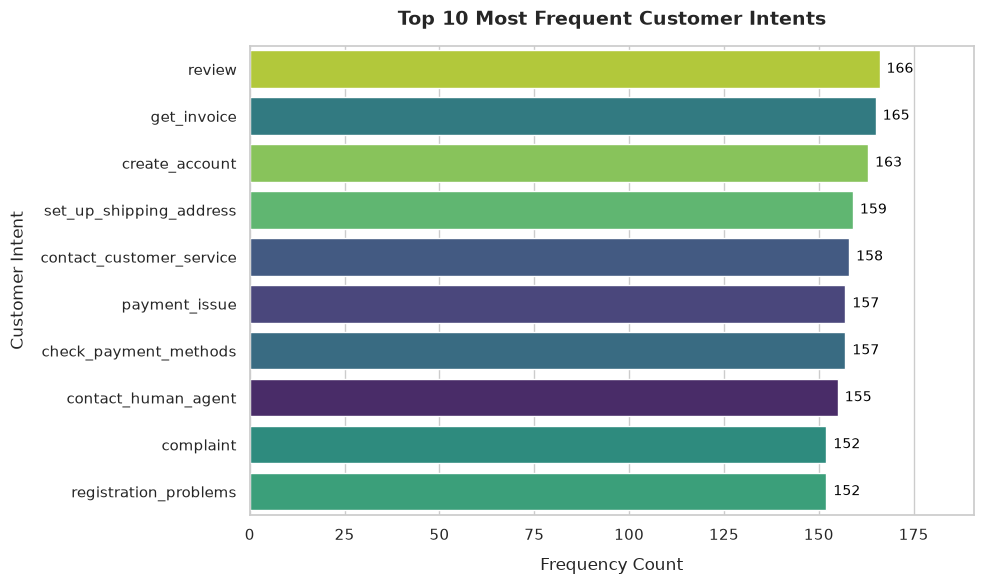

In [16]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate top 10 intent frequencies and proportion
top_10_intents = df_cleaned['intent'].value_counts().head(10).index
total_records = len(df_cleaned)
top_intent_count = df_cleaned['intent'].value_counts().iloc[0]
top_intent_ratio = (top_intent_count / total_records) * 100

print(f"Top 1 Intent: '{df_cleaned['intent'].value_counts().index[0]}'")
print(f"Top 1 Intent Frequency: {top_intent_count} rows ({top_intent_ratio:.2f}% of total data)")

# Check for severe class imbalance (>80% dominance)
if top_intent_ratio > 80:
    print("WARNING: Severe class imbalance detected! A single intent dominates >80% of data.")
else:
    print(" Intent distribution is reasonable (No single intent dominates >80% of data).")

# 2. Set up visual styling
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Create Horizontal Bar Chart using Seaborn
ax = sns.countplot(
    data=df_cleaned[df_cleaned['intent'].isin(top_10_intents)],
    y='intent',
    order=top_10_intents,
    palette="viridis",
    hue='intent',
    legend=False
)

# 4. Add data labels on each bar for clarity
for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f'{int(width):,}',
        (width, p.get_y() + p.get_height() / 2.),
        ha='left', 
        va='center',
        xytext=(5, 0),
        textcoords='offset points',
        fontsize=10,
        color='black'
    )

# 5. Add Titles and Labels
plt.title("Top 10 Most Frequent Customer Intents", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Frequency Count", fontsize=12, labelpad=10)
plt.ylabel("Customer Intent", fontsize=12, labelpad=10)

# Adjust margins to accommodate count labels
plt.xlim(0, max(df_cleaned['intent'].value_counts()) * 1.15)
plt.tight_layout()
plt.show()

#### **1.3.2 Perform Bivariate Analysis [2 marks]**
**The Task:** Read the text from the uploaded Markdown SOP files and fit a `TfidfVectorizer` (with `stop_words='english'`) to transform them into vectors.

**Hints & Tips:**
* Read files into a list of strings first using `open(f, 'r').read()`.
* `TfidfVectorizer(stop_words="english")` removes common words, keeping meaningful terms.
* The resulting matrix shape should be `(num_docs, num_unique_terms)`.

**Learner Inference:** This transforms raw text into math, letting you prove whether your policies are distinct enough for an AI to tell apart.

In [21]:
# YOUR CODE HERE
import os
import glob
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Read the text from all uploaded Markdown SOP files into a list
sop_texts = []
sop_filenames = []

# Sort policy files to maintain consistent ordering across runs
sorted_policy_files = sorted(policy_files)

for filepath in sorted_policy_files:
    filename = os.path.basename(filepath)
    with open(filepath, 'r', encoding='utf-8') as f:
        text = f.read()
        sop_texts.append(text)
        sop_filenames.append(filename)

print(f"Successfully read {len(sop_texts)} SOP Markdown files.")

# 2. Instantiate and fit TfidfVectorizer (removing common English stop words)
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(sop_texts)

# 3. Print the resulting matrix shape and details
num_docs, num_terms = tfidf_matrix.shape
print(f"\n--- TF-IDF Transformation Details ---")
print(f"Number of SOP Documents (Rows)  : {num_docs}")
print(f"Number of Unique Terms (Columns): {num_terms}")
print(f"TF-IDF Matrix Shape             : {tfidf_matrix.shape}")

Successfully read 13 SOP Markdown files.

--- TF-IDF Transformation Details ---
Number of SOP Documents (Rows)  : 13
Number of Unique Terms (Columns): 797
TF-IDF Matrix Shape             : (13, 797)


In [22]:
import random

# Get the full array of unique terms
all_terms = tfidf_vectorizer.get_feature_names_out()

# Pick 15 random terms
random_sample = random.sample(list(all_terms), 15)

print(f"Total Unique Terms (num_terms): {len(all_terms)}")
print("\nSample of 15 Unique Terms:")
print(random_sample)

Total Unique Terms (num_terms): 797

Sample of 15 Unique Terms:
['report', 'digits', 'escalate', 'credit', 'latest', 'honored', 'service', 'orders', 'caused', 'supervisor', 'identify', 'manual', 'opt', 'expires', 'goods']


#### **1.3.3 Generate Visualisations [2 marks]**
**The Task:** Calculate cosine similarity between the TF-IDF vectors of the SOP documents and plot an annotated heatmap.

**Hints & Tips:**
* Use `cosine_similarity` from sklearn and `sns.heatmap` with `annot=True`.
* Diagonal should always be 1.0 (document vs itself).
* Off-diagonal >0.5 = high overlap (RAG may struggle); <0.3 = low overlap (good retrieval).

**Learner Inference:** High overlap (dark off-diagonal squares) means the RAG system struggles to fetch the right doc. Low overlap proves retrieval will be accurate.

--- SOP Similarity Metrics ---
Average Off-Diagonal Similarity: 0.106
Maximum Off-Diagonal Similarity: 0.424

 All SOP documents have low-to-moderate overlap (<0.50). Excellent for retrieval!


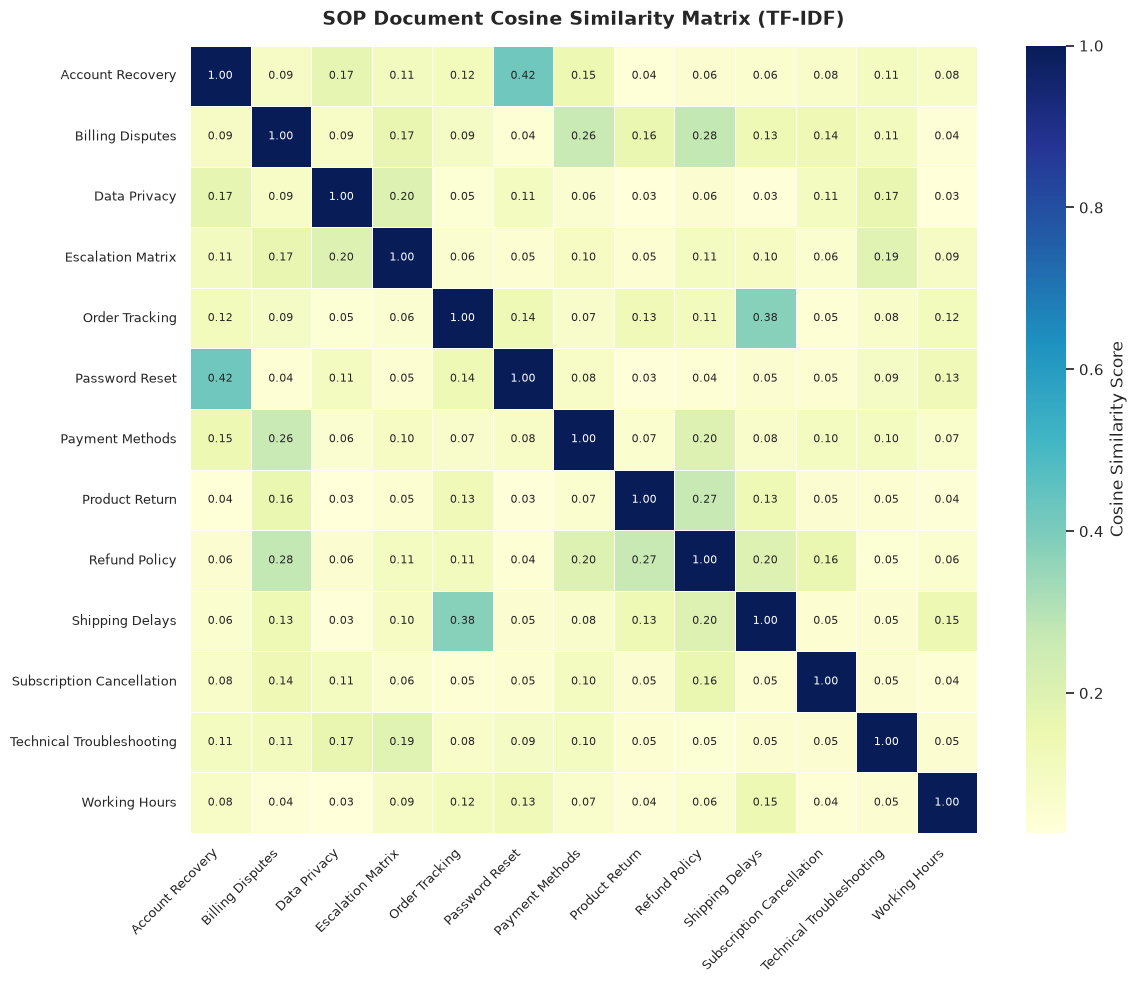

In [24]:
# YOUR CODE HERE
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# 1. Calculate Cosine Similarity Matrix across all SOP documents
similarity_matrix = cosine_similarity(tfidf_matrix)

# 2. Extract clean labels (shortened file names without '.md' extension)
short_labels = [f.replace('.md', '').replace('_', ' ').title() for f in sop_filenames]

# 3. Analyze Off-Diagonal Overlaps
# Mask the diagonal (1.0 self-similarity) to inspect true inter-document overlap
n = len(sop_filenames)
off_diagonal_mask = ~np.eye(n, dtype=bool)
off_diagonal_scores = similarity_matrix[off_diagonal_mask]

max_overlap = off_diagonal_scores.max()
mean_overlap = off_diagonal_scores.mean()

print(f"--- SOP Similarity Metrics ---")
print(f"Average Off-Diagonal Similarity: {mean_overlap:.3f}")
print(f"Maximum Off-Diagonal Similarity: {max_overlap:.3f}")

# Check for high overlap risk (>0.5)
high_overlaps = np.argwhere((similarity_matrix > 0.5) & off_diagonal_mask)
if len(high_overlaps) > 0:
    print(f"\nHigh Overlap Warning (>0.50 similarity) detected between:")
    seen_pairs = set()
    for idx1, idx2 in high_overlaps:
        pair = tuple(sorted([sop_filenames[idx1], sop_filenames[idx2]]))
        if pair not in seen_pairs:
            seen_pairs.add(pair)
            print(f"   - '{pair[0]}' vs '{pair[1]}' (Score: {similarity_matrix[idx1, idx2]:.2f})")
else:
    print("\n All SOP documents have low-to-moderate overlap (<0.50). Excellent for retrieval!")

# 4. Set up Seaborn Heatmap Visualisation
plt.figure(figsize=(12, 10))
sns.set_theme(style="white")

# Plot Heatmap with annotations
ax = sns.heatmap(
    similarity_matrix,
    xticklabels=short_labels,
    yticklabels=short_labels,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={'label': 'Cosine Similarity Score'},
    annot_kws={"size": 8}
)

plt.title("SOP Document Cosine Similarity Matrix (TF-IDF)", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

---
## Save Artifacts for Notebook 2

**IMPORTANT:** This cell saves the cleaned DataFrame. Notebook 2 depends on this file.

In [26]:
# YOUR CODE HERE
import os

# 1. Define output directory and file path
output_dir = "./data"
os.makedirs(output_dir, exist_ok=True)

# Save directly in current directory OR in ./data folder
output_filepath = os.path.join(output_dir, "sampled_data.csv")

# 2. Export cleaned DataFrame to CSV
# index=False ensures pandas doesn't add an unwanted extra 'Unnamed: 0' index column
df_cleaned.to_csv(output_filepath, index=False)

# 3. Also save a copy in the root folder just in case Notebook 2 expects it directly in the working directory
df_cleaned.to_csv("sampled_data.csv", index=False)

# 4. Verify file export and display confirmation
if os.path.exists(output_filepath):
    file_size_kb = os.path.getsize(output_filepath) / 1024
    print(f"Successfully saved artifact: 'sampled_data.csv'")
    print(f"   - File Path            : {output_filepath}")
    print(f"   - Root File Path       : sampled_data.csv")
    print(f"   - Total Rows Exported  : {len(df_cleaned):,}")
    print(f"   - Total Columns        : {len(df_cleaned.columns)}")
    print(f"   - File Size            : {file_size_kb:.2f} KB")
else:
    print("Error: Failed to save 'sampled_data.csv'")

Successfully saved artifact: 'sampled_data.csv'
   - File Path            : ./data/sampled_data.csv
   - Root File Path       : sampled_data.csv
   - Total Rows Exported  : 3,902
   - Total Columns        : 5
   - File Size            : 2712.78 KB


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 2.**

- [ ] Bitext dataset loaded and `.info()` printed
- [ ] Dataset sampled to 4000 rows (or chosen size 1000–5000)
- [ ] Nulls inspected, near-duplicates removed via normalised dedup
- [ ] Top 10 intent bar chart rendered
- [ ] TF-IDF vectorisation completed on SOP documents
- [ ] Cosine similarity heatmap rendered
- [ ] **`sampled_data.csv` saved to disk** ← _CRITICAL for Notebook 2_
- [ ] `corporate_policies/` folder still accessible ← _Needed in Notebooks 2 and 4_

**If any item is unchecked, fix it before moving on.**